In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input, MultiHeadAttention, LayerNormalization, Flatten, Reshape, Dropout
import xgboost as xgb
import joblib
from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.metrics import roc_curve, roc_auc_score
from IPython.display import display, HTML
import warnings
warnings.filterwarnings("ignore")

In [2]:
data = pd.read_csv('heart.csv')

In [3]:
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [4]:
data.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1
1024,54,1,0,120,188,0,1,113,0,1.4,1,1,3,0


In [5]:
data.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [6]:
data.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


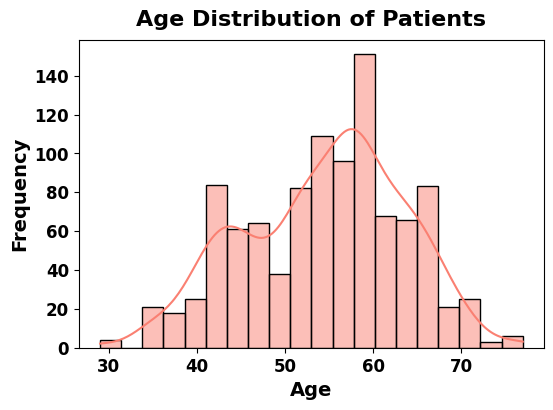

In [8]:
plt.figure(figsize=(6, 4))
sns.histplot(data['age'], bins=20, kde=True, color='salmon')
plt.title('Age Distribution of Patients', fontsize=16, fontweight='bold', pad=10)
plt.xlabel('Age', fontsize=14, fontweight='bold')
plt.ylabel('Frequency', fontsize=14, fontweight='bold')
plt.xticks(fontweight='bold', fontsize=12)
plt.yticks(fontweight='bold', fontsize=12)
plt.show()

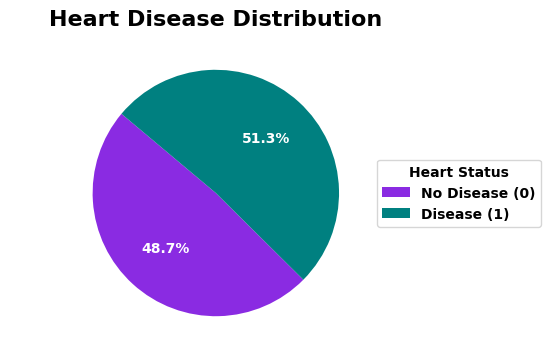

In [9]:
plt.figure(figsize=(6, 4))

target_counts = data['target'].value_counts().sort_index() 
labels = [f"No Disease (0)" if val == 0 else f"Disease (1)" for val in target_counts.index]
colors = ['blueviolet', 'teal'] 

# Draw pie
wedges, texts, autotexts = plt.pie(
    target_counts,
    labels=labels,              
    autopct='%1.1f%%',          
    colors=colors,
    startangle=140,
    textprops={'color':'white', 'fontweight':'bold'},  
    labeldistance=1.1,
    pctdistance=0.6
)

plt.legend(
    wedges, 
    labels, 
    title="Heart Status", 
    title_fontproperties={'weight':'bold'}, 
    prop={'weight':'bold'},                  
    loc="center left", 
    bbox_to_anchor=(1, 0, 0.5, 1)
)

plt.title('Heart Disease Distribution', fontsize=16, fontweight='bold', pad=10)
plt.show()

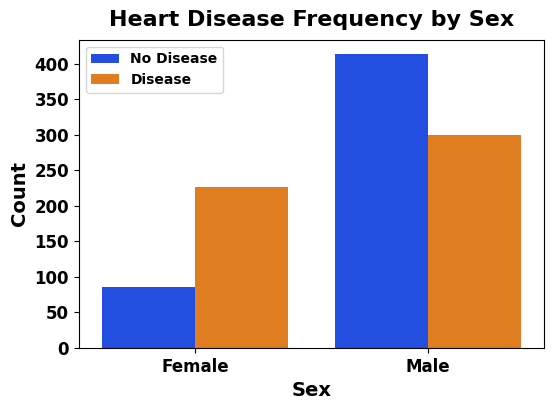

In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(
    x='sex',
    hue='target',
    data=data,
    palette="bright" 
)
plt.title('Heart Disease Frequency by Sex', fontsize=16, fontweight='bold', pad=10)
plt.xlabel('Sex', fontsize=14, fontweight='bold')
plt.ylabel('Count', fontsize=14, fontweight='bold')
plt.xticks(ticks=[0, 1], labels=['Female', 'Male'], fontweight='bold', fontsize=12)
plt.legend(['No Disease', 'Disease'], prop={'weight': 'bold'})
plt.yticks(fontweight='bold', fontsize=12)
plt.show()

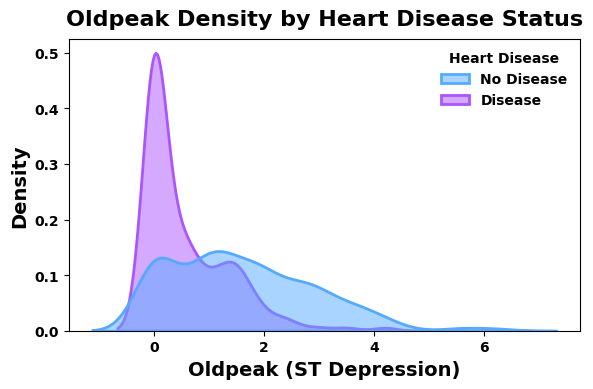

In [11]:
plt.figure(figsize=(6, 4))
temp_data = data.copy()
temp_data['target_label'] = temp_data['target'].map({0: 'No Disease', 1: 'Disease'})
ax = sns.kdeplot(
    data=temp_data,
    x='oldpeak',
    hue='target_label',
    fill=True,
    palette='cool',                         
    linewidth=2,
    alpha=0.5
)

plt.title('Oldpeak Density by Heart Disease Status', fontsize=16, fontweight='bold', pad=10)
plt.xlabel('Oldpeak (ST Depression)', fontsize=14, fontweight='bold')
plt.ylabel('Density', fontsize=14, fontweight='bold')

sns.move_legend(
    ax,
    "upper right",
    title='Heart Disease',
    prop={'weight': 'bold'},
    title_fontproperties={'weight': 'bold'},
    frameon=False
)

plt.xticks(fontweight='bold')
plt.yticks(fontweight='bold')
plt.tight_layout()
plt.show()

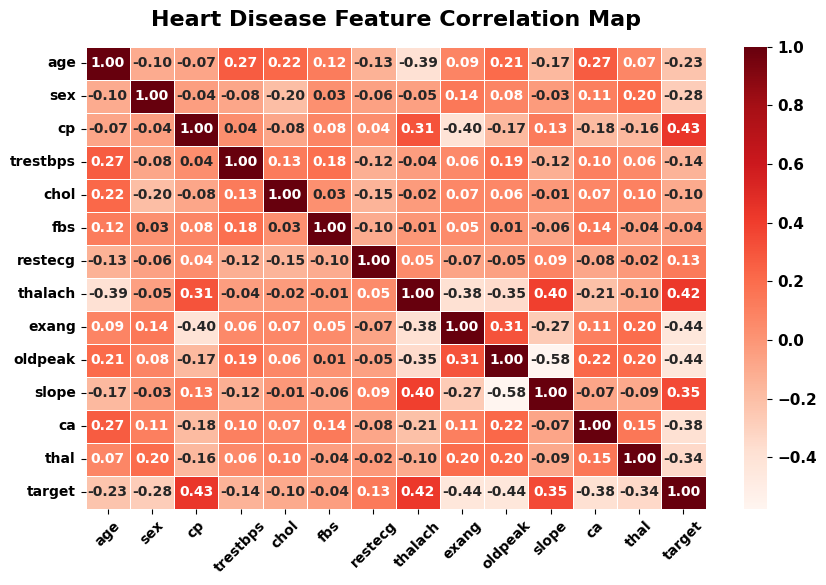

In [12]:
plt.figure(figsize=(10, 6)) 
corr_matrix = data.corr()

ax = sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='Reds', 
    linewidths=0.5,
    annot_kws={'weight': 'bold', 'size': 10}
)
plt.title(
    'Heart Disease Feature Correlation Map',
    fontsize=16,
    fontweight='bold',
    pad=15
)
plt.xticks(fontweight='bold', rotation=45)
plt.yticks(fontweight='bold', rotation=0)
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=11)
for tick in cbar.ax.get_yticklabels():
    tick.set_fontweight('bold')
plt.show()

In [13]:
X = data.drop('target', axis=1)
y = data['target']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [14]:
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

In [15]:
def build_tuning_model(input_dim):
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(128, activation='relu', input_shape=(input_dim,)),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])
    return model

def snow_leopard_optimization(pop_size=10):
    best_lr = 0.001
    best_score = 0
    print("SLO is searching for the best hyper-parameters...")
    
    for i in range(pop_size):
        lr_candidate = np.random.uniform(0.0001, 0.01)
        model = build_tuning_model(X_train.shape[1])
        model.compile(optimizer=tf.keras.optimizers.Adam(lr_candidate), loss='binary_crossentropy', metrics=['accuracy'])
        
        hist = model.fit(X_train, y_train, epochs=10, verbose=0)
        score = hist.history['accuracy'][-1]
        
        if score > best_score:
            best_score = score
            best_lr = lr_candidate
            
    print(f"SLO Finished! Best Learning Rate found: {best_lr}")
    return best_lr

In [16]:
best_lr = snow_leopard_optimization()

SLO is searching for the best hyper-parameters...
SLO Finished! Best Learning Rate found: 0.008092435234860577


In [17]:
def build_raxt_net(input_dim):
    inputs = Input(shape=(input_dim,))
    x = Dense(128, activation='relu')(inputs)
    x = Dropout(0.4)(x)

    x_reshaped = Reshape((1, 128))(x)
    attn_out = MultiHeadAttention(num_heads=8, key_dim=16)(x_reshaped, x_reshaped)
    x_attn = LayerNormalization()(tf.keras.layers.Add()([x_reshaped, attn_out]))
    x_feat = Flatten()(x_attn)

    x_dense = Dense(64, activation='relu')(x_feat)
    outputs = Dense(1, activation='sigmoid')(x_dense)
    
    model = Model(inputs=inputs, outputs=outputs)
    feat_extractor = Model(inputs=inputs, outputs=x_feat)
    return model, feat_extractor

raxt_model, raxt_feat_extractor = build_raxt_net(X_train.shape[1])
raxt_model.compile(optimizer=tf.keras.optimizers.Adam(best_lr), 
                   loss='binary_crossentropy', 
                   metrics=['accuracy'])

history = raxt_model.fit(
    X_train, y_train, 
    epochs=100, 
    validation_data=(X_test, y_test), 
    verbose=1 
)

X_train_attn = raxt_feat_extractor.predict(X_train)
X_test_attn = raxt_feat_extractor.predict(X_test)

model_xgb = xgb.XGBClassifier(learning_rate=best_lr, n_estimators=200, max_depth=7, use_label_encoder=False, eval_metric='logloss')
model_xgb.fit(X_train_attn, y_train)

model_tab = TabNetClassifier(verbose=0)
model_tab.fit(X_train, y_train, max_epochs=100)

raxt_probs = raxt_model.predict(X_test).flatten()
xgb_probs = model_xgb.predict_proba(X_test_attn)[:, 1]
tab_probs = model_tab.predict_proba(X_test)[:, 1]

final_probs = (0.45 * raxt_probs) + (0.50 * xgb_probs) + (0.05 * tab_probs)
final_preds = (final_probs > 0.5).astype(int)

Epoch 1/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.8037 - loss: 0.5173 - val_accuracy: 0.8146 - val_loss: 0.4213
Epoch 2/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8634 - loss: 0.3461 - val_accuracy: 0.8341 - val_loss: 0.3759
Epoch 3/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8902 - loss: 0.2821 - val_accuracy: 0.8634 - val_loss: 0.3808
Epoch 4/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9122 - loss: 0.2725 - val_accuracy: 0.8634 - val_loss: 0.3206
Epoch 5/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9037 - loss: 0.2768 - val_accuracy: 0.8634 - val_loss: 0.3135
Epoch 6/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9049 - loss: 0.2493 - val_accuracy: 0.8634 - val_loss: 0.3279
Epoch 7/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9098 - loss: 0.2395 - val_accuracy: 0.8585 - val_loss: 0.3067
Epoch 8/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9000 - loss: 0.2518 - val_accuracy: 0.8829 - 

In [18]:
print("\n" + "="*80)
print(f"RAXT-Net Hybrid Ensemble With Snow Leopard Optimization Test Accuracy: {accuracy_score(y_test, final_preds)*100:.2f}%")
print("="*80)


RAXT-Net Hybrid Ensemble With Snow Leopard Optimization Test Accuracy: 98.54%


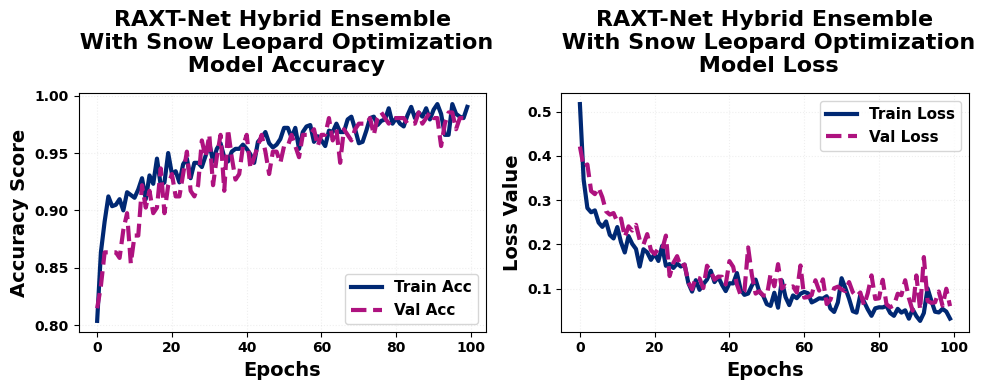

In [19]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc', color="#002873", linewidth=3)
plt.plot(history.history['val_accuracy'], label='Val Acc', color="#ae127f", linestyle='--', linewidth=3) 

plt.title('RAXT-Net Hybrid Ensemble\n With Snow Leopard Optimization\n Model Accuracy', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Epochs', fontsize=14, fontweight='bold')
plt.ylabel('Accuracy Score', fontsize=14, fontweight='bold')
plt.xticks(fontweight='bold')
plt.yticks(fontweight='bold')
plt.legend(loc='lower right', prop={'weight': 'bold', 'size': 11})
plt.grid(True, alpha=0.2, linestyle=':')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', color='#002873', linewidth=3)
plt.plot(history.history['val_loss'], label='Val Loss', color='#ae127f', linestyle='--', linewidth=3) 

plt.title('RAXT-Net Hybrid Ensemble\n With Snow Leopard Optimization\n Model Loss', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Epochs', fontsize=14, fontweight='bold')
plt.ylabel('Loss Value', fontsize=14, fontweight='bold')
plt.xticks(fontweight='bold')
plt.yticks(fontweight='bold')
plt.legend(loc='upper right', prop={'weight': 'bold', 'size': 11})
plt.grid(True, alpha=0.2, linestyle=':')

plt.tight_layout()
plt.show()

In [20]:
target_names = ['No Disease', 'Disease']

print("\n" + "="*60)
print(f"RAXT-Net Hybrid Ensemble With Snow Leopard Optimization\nClassification Report")
print("="*60)

print(classification_report(y_test, final_preds, target_names=target_names, digits=4))


RAXT-Net Hybrid Ensemble With Snow Leopard Optimization
Classification Report
              precision    recall  f1-score   support

  No Disease     0.9714    1.0000    0.9855       102
     Disease     1.0000    0.9709    0.9852       103

    accuracy                         0.9854       205
   macro avg     0.9857    0.9854    0.9854       205
weighted avg     0.9858    0.9854    0.9854       205



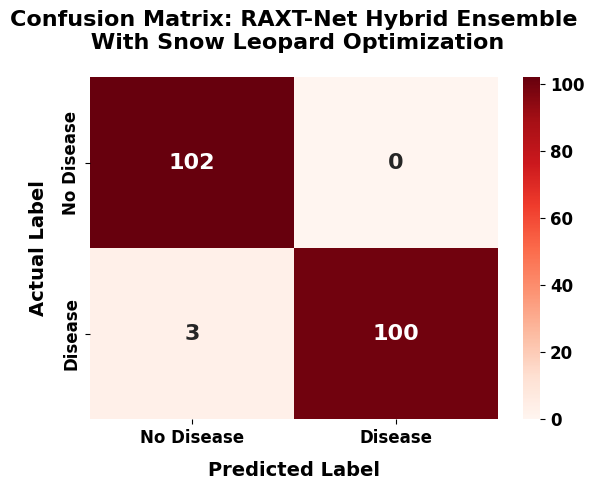

In [26]:
cm = confusion_matrix(y_test, final_preds)

labels = ["No Disease", "Disease"]

plt.figure(figsize=(6, 5))

ax = sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Reds', 
    annot_kws={"size": 16, "weight": "bold"}, 
    cbar=True,
    xticklabels=labels, 
    yticklabels=labels
)

plt.xlabel("Predicted Label", fontsize=14, fontweight='bold', labelpad=10)
plt.ylabel("Actual Label", fontsize=14, fontweight='bold', labelpad=10)
plt.title("Confusion Matrix: RAXT-Net Hybrid Ensemble\n With Snow Leopard Optimization", fontsize=16, fontweight='bold', pad=20)

plt.xticks(fontsize=12, fontweight='bold')
plt.yticks(fontsize=12, fontweight='bold')


cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=12)
for label in cbar.ax.get_yticklabels():
    label.set_fontweight('bold')

plt.tight_layout()
plt.show()

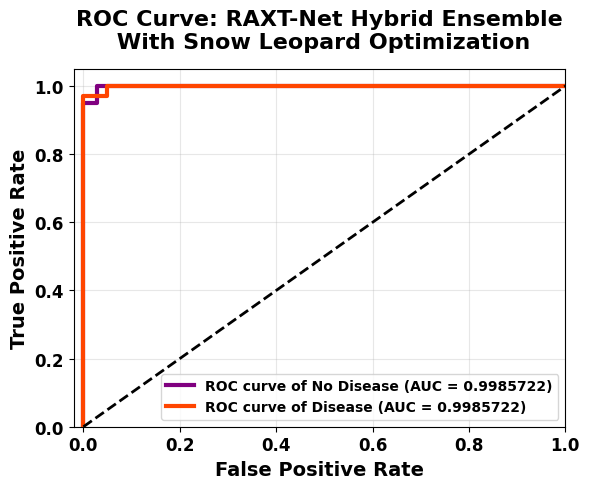

In [27]:
y_test_bin = label_binarize(y_test, classes=[0, 1])
n_classes = 2
target_names = ['No Disease', 'Disease']
colors = ['purple', 'orangered']

y_score = np.vstack([(1 - final_probs), final_probs]).T

plt.figure(figsize=(6, 5))


for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, 0] if i == 0 else y_test_bin[:, 0], 
                            y_score[:, i], 
                            pos_label=i)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[i], lw=3,
             label=f'ROC curve of {target_names[i]} (AUC = {roc_auc:.7f})')

plt.plot([0, 1], [0, 1], color='black', lw=2, linestyle='--')

plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=14, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=14, fontweight='bold')
plt.title('ROC Curve: RAXT-Net Hybrid Ensemble\n With Snow Leopard Optimization', fontsize=16, fontweight='bold', pad=15)

plt.xticks(fontsize=12,fontweight='bold')
plt.yticks(fontsize=12,fontweight='bold')
plt.legend(loc="lower right", prop={'weight':'bold', 'size':10})
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
raxt_model.save('raxt_model.h5')
raxt_feat_extractor.save('raxt_feat_extractor.h5')
model_xgb.save_model('model_xgb.json')
model_tab.save_model('./tabnet_model_checkpoint')

Successfully saved model at ./tabnet_model_checkpoint.zip


'./tabnet_model_checkpoint.zip'

In [2]:
raxt_model = tf.keras.models.load_model('raxt_model.h5')
raxt_feat_extractor = tf.keras.models.load_model('raxt_feat_extractor.h5')
model_xgb = xgb.XGBClassifier()
model_xgb.load_model('model_xgb.json')
model_tab = TabNetClassifier()
model_tab.load_model('tabnet_model_checkpoint.zip')

scaler = joblib.load('scaler.pkl')
print("model loaded Successfully")

model loaded Successfully


In [3]:
feature_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal"]
new_values = [52.0, 1.0, 0.0, 125.0, 212.0, 0.0, 1.0, 168.0, 0.0, 1.0, 2.0, 2.0, 3.0]
input_df = pd.DataFrame([new_values], columns=feature_names)

input_scaled = scaler.transform(input_df)

raxt_prob = raxt_model.predict(input_scaled, verbose=0).flatten()[0]

deep_features = raxt_feat_extractor.predict(input_scaled, verbose=0)
xgb_prob = model_xgb.predict_proba(deep_features)[:, 1][0]

tab_prob = model_tab.predict_proba(input_scaled)[:, 1][0]

final_prob = (0.35 * raxt_prob) + (0.35 * xgb_prob) + (0.30 * tab_prob)
final_pred = 1 if final_prob > 0.5 else 0

In [4]:
label = "HEART DISEASE DETECTED" if final_pred == 1 else "NO HEART DISEASE DETECTED"
color = "#c0392b" if final_pred == 1 else "#27ae60"
confidence = (final_prob if final_pred == 1 else (1 - final_prob)) * 100

html_card = f"""
<div style="border:3px solid #34495e; border-radius:15px; padding:25px; width:480px; font-family: 'Segoe UI', Arial, sans-serif; background-color:#ffffff; box-shadow: 0 8px 16px rgba(0,0,0,0.2); margin:auto;">
    <h2 style="color:#c0392b; text-align:center; margin-top:0; font-weight: 800; letter-spacing: 1px;">❤️ CARDIOVASCULAR DIAGNOSIS</h2>
    <p style="text-align:center; color:#2c3e50; font-size:15px; font-weight: 700;">Hybrid Ensemble: RAxT + XGBoost + TabNet</p>
    <hr style="border:1.5px solid #ecf0f1; width:90%;">
    
    <div style="margin:25px 0;">
        <p style="margin:5px 0; font-size:16px; font-weight: 800; color: #34495e;">DIAGNOSIS RESULT:</p>
        <div style="background-color:{color}; color:white; padding:15px; border-radius:10px; font-weight: 900; text-align:center; font-size:22px; text-transform: uppercase; letter-spacing: 1px; box-shadow: inset 0 0 10px rgba(0,0,0,0.1);">
            {label}
        </div>
    </div>
    
    <div style="display:flex; justify-content:space-between; align-items: center; font-size:18px; background:#f1f2f6; padding:15px; border-radius:8px; border-left: 5px solid #2980b9;">
        <span style="font-weight: 800; color: #2c3e50;">CONFIDENCE SCORE:</span>
        <span style="color:#2980b9; font-weight: 900; font-size: 22px;">{confidence:.2f}%</span>
    </div>
    
    <div style="margin-top:20px; font-size:13px; color:#2c3e50; border-top: 2px solid #ecf0f1; padding-top:15px;">
        <p style="text-align:center; font-weight: 800; margin-bottom: 10px; text-decoration: underline;">ENSEMBLE COMPONENT PROBABILITIES</p>
        <div style="display: flex; justify-content: space-around; text-align: center;">
            <div>
                <p style="margin:0; font-weight: 900; color: #e67e22;">RAxT-Net</p>
                <p style="margin:0; font-size: 14px; color: #7f8c8d;">Residual Attention</p>
                <p style="margin:5px 0 0 0; font-weight: 800; color: #2c3e50;">{raxt_prob:.4f}</p>
            </div>
            <div style="border-left: 1px solid #bdc3c7;"></div>
            <div>
                <p style="margin:0; font-weight: 900; color: #2980b9;">XGBoost</p>
                <p style="margin:0; font-size: 14px; color: #7f8c8d;">Gradient Boosting</p>
                <p style="margin:5px 0 0 0; font-weight: 800; color: #2c3e50;">{xgb_prob:.4f}</p>
            </div>
            <div style="border-left: 1px solid #bdc3c7;"></div>
            <div>
                <p style="margin:0; font-weight: 900; color: #27ae60;">TabNet</p>
                <p style="margin:0; font-size: 14px; color: #7f8c8d;">Attention Tabular</p>
                <p style="margin:5px 0 0 0; font-weight: 800; color: #2c3e50;">{tab_prob:.4f}</p>
            </div>
        </div>

    </div>
</div>
"""
display(HTML(html_card))